In [ ]:
## Is there overlap between Reform/Corbynism / are Reform representing The Poor?

In [2]:
%%time
dataset_name = "W29_comb"
df_list = "BES_Panel"

%matplotlib inline 
%run BES_header.py {dataset_name} {df_list}

global BES_label_list, BES_df_list

Toggle code

FileNotFoundError: [Errno 2] No such file or directory: '..\\BES_analysis_data\\W29_comb\\BES2024_W29_Panel_v29A.0.zip'

CPU times: total: 4.03 s
Wall time: 3min 18s


In [9]:
columns_minus_oslaua = [x for x in df.columns if "oslauaW29" not in x]

In [ ]:
# oslauaW29 

In [7]:
oslauaW29 = df["oslauaW29"]

In [10]:
df_fixed = pd.read_stata('..\\BES_analysis_data\\W29_comb\\BES2024_W29_Panel_v29A.0.dta',columns=columns_minus_oslaua )

In [11]:
search(df_fixed,"oslaua")

oslauaW1           30364
oslaua_codeW1     118700
oslauaW2           30889
oslaua_codeW2     118700
oslauaW3           28104
oslaua_codeW3     118700
oslauaW4           31427
oslaua_codeW4     118700
oslauaW5           30809
oslaua_codeW5     118700
oslauaW6           30131
oslaua_codeW6     118700
oslauaW7           30895
oslaua_codeW7     118700
oslauaW8           33501
oslaua_codeW8     118700
oslauaW9           30015
oslaua_codeW9     118700
oslauaW10          30213
oslaua_codeW10    118700
oslauaW11          30936
oslaua_codeW11    118700
oslauaW12          34393
oslaua_codeW12    118700
oslauaW13          31135
oslaua_codeW13    118700
oslauaW14          31063
oslaua_codeW14    118700
oslauaW15          30841
oslaua_codeW15    118700
oslauaW16          37959
oslaua_codeW16    118700
oslauaW17          34365
oslaua_codeW17    118700
oslauaW18          37824
oslaua_codeW18    118700
oslauaW19          32176
oslaua_codeW19    118700
oslauaW20          31468
oslaua_codeW20    118700


In [41]:
W26_dict= df_fixed[["oslaua_codeW26","oslauaW26"]].replace("",np.nan).dropna().set_index("oslaua_codeW26").to_dict()['oslauaW26']
W27_dict= df_fixed[["oslaua_codeW27","oslauaW27"]].replace("",np.nan).dropna().set_index("oslaua_codeW27").to_dict()['oslauaW27']
W28_dict= df_fixed[["oslaua_codeW28","oslauaW28"]].replace("",np.nan).dropna().set_index("oslaua_codeW28").to_dict()['oslauaW28']

# W26_dict + W27_dict + W28_dict

dic2 = dict(W26_dict, **W27_dict)
dic2 = dict(dic2, **W28_dict)
# dic2 = {W26_dict, **W27_dict}
len( dic2 )

df_fixed["oslauaW29"] = df_fixed["oslaua_codeW29"].apply(lambda x: dic2[x] if x!='' else np.nan)

In [47]:
df_fixed.to_pickle('..\\BES_analysis_data\\W29_comb\\BES2024_W29_Panel_v29A.0.zip',compression='zip')

In [16]:
df_fixed["oslaua_codeW28"]

0          
1          
2          
3          
4          
         ..
118695     
118696     
118697     
118698     
118699     
Name: oslaua_codeW28, Length: 118700, dtype: object

In [46]:
import os
os.getcwd()

'E:\\Users\\Gamer\\Documents\\GitHub\\BES_analysis\\BES_analysis_code'

In [48]:
BES_Panel=df_fixed

In [49]:
like_list = [x for x in search(BES_Panel,"like.*W19").index if x not in ["likePriceW19","likePCW19","likelyBrexitW19"]]

In [50]:
BES_Panel[like_list]\
    .apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan))\
    .corr()["likeCorbynW19"].sort_values()

likeConW19           -0.574651
likeJohnsonW19       -0.541915
likeBrexitPartyW19   -0.395896
likeFarageW19        -0.382000
likeDaveyW19          0.228350
likeSwinsonW19        0.242641
likeLDW19             0.262229
likePhillipsW19       0.272513
likeMoranW19          0.356061
likeBartleyW19        0.376729
likeBerryW19          0.463493
likeGrnW19            0.488496
likeStarmerW19        0.492916
likeSNPW19            0.534903
likeSturgeonW19       0.546229
likeRaynerW19         0.579758
likeLongBaileyW19     0.635796
likeLabW19            0.791862
likeCorbynW19         1.000000
Name: likeCorbynW19, dtype: float64

In [53]:
search(BES_Panel,"like.*W29").index

Index(['likeSunakW29', 'likeStarmerW29', 'likeDaveyW29', 'likeSwinneyW29',
       'likeIorwerthW29', 'likeFarageW29', 'likeRamsayW29', 'likeDenyerW29',
       'likeHarvieW29', 'likeSlaterW29', 'likeConW29', 'likeLabW29',
       'likeLDW29', 'likeSNPW29', 'likePCW29', 'likeBrexitPartyW29',
       'likeGrnW29'],
      dtype='object')

In [56]:
like_list = [x for x in search(BES_Panel,"like.*W29").index if x not in ["likePriceW19","likePCW19","likelyBrexitW19"]]+["likeCorbynW19"]

In [58]:
BES_Panel[like_list]\
    .apply(lambda x: x.replace("Don't know",np.nan).cat.codes.replace(-1,np.nan))\
    .corr()["likeCorbynW19"].sort_values().drop("likeCorbynW19")

likeConW29           -0.452716
likeBrexitPartyW29   -0.373303
likeFarageW29        -0.364171
likeSunakW29         -0.328228
likeLDW29             0.281656
likeDaveyW29          0.292831
likeIorwerthW29       0.332216
likeSwinneyW29        0.379542
likeSNPW29            0.383704
likePCW29             0.399976
likeStarmerW29        0.401174
likeSlaterW29         0.405169
likeHarvieW29         0.415267
likeRamsayW29         0.436863
likeGrnW29            0.471895
likeLabW29            0.487853
likeDenyerW29         0.501169
Name: likeCorbynW19, dtype: float64

In [64]:
likeCorbyn_dict = {1:'likeCorbynW7',2:'likeCorbynW7',3:'likeCorbynW7',4:'likeCorbynW7',5:'likeCorbynW7',6:'likeCorbynW7',
 7:'likeCorbynW7', 8:'likeCorbynW8', 9:'likeCorbynW9', 10:'likeCorbynW10',
       11:'likeCorbynW11', 12:'likeCorbynW12', 13:'likeCorbynW13', 14:'likeCorbynW14',
       15:'likeCorbynW15', 16:'likeCorbynW16', 17:'likeCorbynW17', 18:'likeCorbynW18',
       19:'likeCorbynW19',
 20:'likeCorbynW19',
 21:'likeCorbynW19',
 22:'likeCorbynW19',
 23:'likeCorbynFormerW25',
 24:'likeCorbynFormerW25',
 25:'likeCorbynFormerW25',
26:'likeCorbynFormerW25',
27:'likeCorbynFormerW25',
28:'likeCorbynFormerW25',
29:'likeCorbynFormerW25'
}

In [67]:
party_list = ["Con","Lab","LD","Grn","BNP","UKIP","BrexitParty","PC","SNP",]
Corbyn_corr = pd.DataFrame(columns = ["wave","party","corr","N"])
ind = 0
for wave in range(1,30):
    for party in party_list:
        var_name = "like"+party+"W"+str(wave)
        if var_name in BES_Panel.columns:
            target_party_like =        BES_Panel[var_name].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)
            corbyn_like = BES_Panel[likeCorbyn_dict[wave]].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)
            corr = target_party_like.corr(corbyn_like)
            N = (target_party_like.notnull()&corbyn_like.notnull()).sum()
            Corbyn_corr.loc[ind] = [wave, party, corr, N]
            ind=ind+1

In [99]:
wave_to_date = BES_file_manifest[BES_file_manifest["Only_or_Combined"]=="Only"].set_index("Wave No")["Date_Start"]
wave_to_date.loc[26] = 'Apr-24'
wave_to_date.loc[27] = 'May-24'
wave_to_date.loc[28] = 'Jun-24'
wave_to_date.loc[29] = 'Jul-24'

wave_to_date = pd.to_datetime(wave_to_date,format="%b-%y")

party_color_dict = {"Con":'blue',"Lab":'red',"LD":'orange',"Grn":'green',"BNP":'black',"UKIP":'purple',"BrexitParty":'cyan',"PC":'olive',"SNP":'yellow',}

Corbyn_corr["date"] = Corbyn_corr["wave"].apply(lambda x: wave_to_date[x])

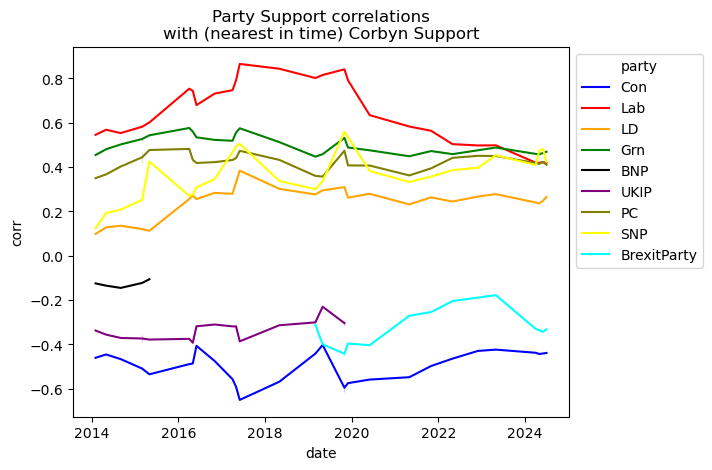

In [100]:
ax = sns.lineplot(data = Corbyn_corr,x="date",hue="party",y="corr",palette=party_color_dict);
plt.title("Party Support correlations\nwith (nearest in time) Corbyn Support");
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
# same size worse for PC/SNP but *adequate* for use here

In [103]:
search(BES_Panel,"likeJohnson")

likeJohnsonW7           30895
likeJohnsonW8           33501
likeJohnsonW9           30035
likeJohnsonW13          15439
likeJohnsonW14           7691
likeJohnsonW15          30842
likeJohnsonW17          34365
likeJohnsonW18          37824
likeJohnsonW19          32176
likeJohnsonW20          31468
likeJohnsonW21          30281
likeJohnsonW22          28113
likeJohnsonW23          30949
likeJohnsonFormerW24    15345
likeJohnsonFormerW25    30407
dtype: int64

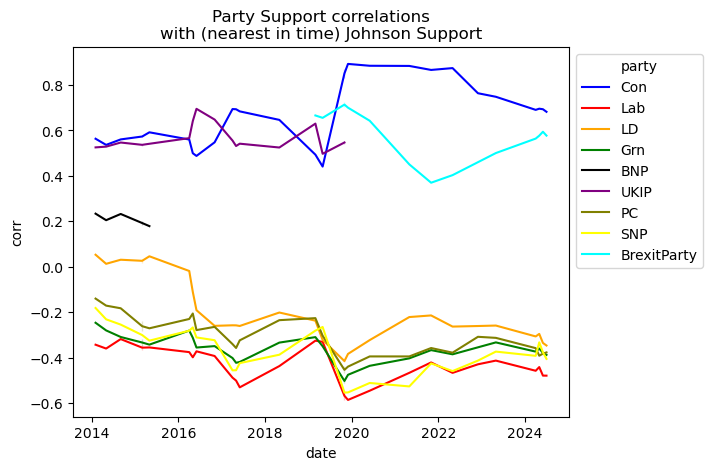

In [105]:
likeJohnson_dict = {1:'likeJohnsonW7',2:'likeJohnsonW7',3:'likeJohnsonW7',4:'likeJohnsonW7',5:'likeJohnsonW7',6:'likeJohnsonW7',
 7:'likeJohnsonW7', 8:'likeJohnsonW8', 9:'likeJohnsonW9', 10:'likeJohnsonW9',
       11:'likeJohnsonW13', 12:'likeJohnsonW13', 13:'likeJohnsonW13', 14:'likeJohnsonW14',
       15:'likeJohnsonW15', 16:'likeJohnsonW15', 17:'likeJohnsonW17', 18:'likeJohnsonW18',
       19:'likeJohnsonW19',
 20:'likeJohnsonW20',
 21:'likeJohnsonW21',
 22:'likeJohnsonW22',
 23:'likeJohnsonW23',
 24:'likeJohnsonFormerW24',
 25:'likeJohnsonFormerW25',
26:'likeJohnsonFormerW25',
27:'likeJohnsonFormerW25',
28:'likeJohnsonFormerW25',
29:'likeJohnsonFormerW25'
}

party_list = ["Con","Lab","LD","Grn","BNP","UKIP","BrexitParty","PC","SNP",]
Corbyn_corr = pd.DataFrame(columns = ["wave","party","corr","N"])
ind = 0
for wave in range(1,30):
    for party in party_list:
        var_name = "like"+party+"W"+str(wave)
        if var_name in BES_Panel.columns:
            target_party_like =        BES_Panel[var_name].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)
            corbyn_like = BES_Panel[likeJohnson_dict[wave]].replace("Don't know",np.nan).cat.codes.replace(-1,np.nan)
            corr = target_party_like.corr(corbyn_like)
            N = (target_party_like.notnull()&corbyn_like.notnull()).sum()
            Corbyn_corr.loc[ind] = [wave, party, corr, N]
            ind=ind+1

Corbyn_corr["date"] = Corbyn_corr["wave"].apply(lambda x: wave_to_date[x])

ax = sns.lineplot(data = Corbyn_corr,x="date",hue="party",y="corr",palette=party_color_dict);
plt.title("Party Support correlations\nwith (nearest in time) Johnson Support");
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [167]:
BES_Panel["borrowEssentialsW26W27"]

0         NaN
1         NaN
2         NaN
3         NaN
4         NaN
         ... 
118695    NaN
118696    NaN
118697    NaN
118698    NaN
118699    NaN
Name: borrowEssentialsW26W27, Length: 118700, dtype: category
Categories (3, object): ['No' < 'Yes' < 'Don't know']

In [183]:
search(BES_Panel,"smallEmergency")

smallEmergency_1W14        31063
smallEmergency_2W14        31063
smallEmergency_3W14        31063
smallEmergency_4W14        31063
smallEmergency_5W14        31063
smallEmergency2_1W23       30949
smallEmergency2_6W23       30949
smallEmergency2_2W23       30949
smallEmergency2_3W23       30949
smallEmergency2_4W23       30949
smallEmergency2_5W23       30949
smallEmergency2_1W25       30407
smallEmergency2_6W25       30407
smallEmergency2_2W25       30407
smallEmergency2_3W25       30407
smallEmergency2_4W25       30407
smallEmergency2_5W25       30407
smallEmergency2_1W26W27    32395
smallEmergency2_6W26W27    32395
smallEmergency2_2W26W27    32395
smallEmergency2_3W26W27    32395
smallEmergency2_4W26W27    32395
smallEmergency2_5W26W27    32395
dtype: int64

In [ ]:
# p_housingW29, voted_ge_2024W29, generalElectionVoteW29, p_gross_household

# borrowEssentials 14/23/25/26&27, smallEmergency_X 14/23/25/26&27

# allSourceIncome

# homeamtb (mort/own), buyHouseYear, homeFinance (access to house finance), inheritMoney, inheritChangeCircs if inheritMoney==1
# mortgagePayment if homeOwn==2, secondHome if homeOwn==1 or homeOwn==2, secondHomeAmtb
# rentPayment rentPayment if, buyHomeFuture
# savings, savingsAmtb, debt, debtAmtb

In [137]:
BES_Panel["generalElectionVoteW29"].cat.categories

replace_dict = {'Conservative':"CON", 'Labour':"LAB", 'Liberal Democrat':"LD",
       'Scottish National Party (SNP)':"SNP", 'Plaid Cymru':"PC", 'Green Party':"GP", 'Other':"OTH",
       'Brexit Party/Reform UK':"REFUK", 'An independent candidate':"OTH", "Don't know":np.nan}
vote2024 = BES_Panel["generalElectionVoteW29"].astype('object').replace(replace_dict)
vote2024.loc[BES_Panel["voted_ge_2024W29"]=='No, did not vote'] = "DNV"
vote2024.value_counts()

generalElectionVoteW29
LAB      9471
CON      5634
REFUK    4039
DNV      3990
LD       3607
GP       1982
OTH       891
SNP       712
PC        242
Name: count, dtype: int64

In [143]:
BES_Panel["p_gross_householdW29"].value_counts()

p_gross_householdW29
Prefer not to answer               6137
Â£70,000 to Â£99,999 per year      2511
Â£20,000 to Â£24,999 per year      2229
Â£25,000 to Â£29,999 per year      2172
Â£50,000 to Â£59,999 per year      1937
Â£30,000 to Â£34,999 per year      1880
Â£10,000 to Â£14,999 per year      1879
Don't know                         1803
Â£15,000 to Â£19,999 per year      1800
Â£35,000 to Â£39,999 per year      1615
Â£40,000 to Â£44,999 per year      1491
Â£60,000 to Â£69,999 per year      1441
Â£45,000 to Â£49,999 per year      1240
Â£100,000 to Â£149,999 per year    1129
Â£5,000 to Â£9,999 per year         858
Â£150,000 and over                  436
under Â£5,000 per year              429
Name: count, dtype: int64

In [141]:
BES_Panel["p_housingW29"].cat.categories

replace_dict = {'Own â outright':"OWN", 'Own â with a mortgage':"MORT",
       'Own (part-own) â through shared ownership scheme (i.e. pay part mortgage, part rent)':"OTH",
       'Rent â from a private landlord':"RENT-PR", 'Rent â from my local authority':"RENT-LA",
       'Rent â from a housing association':"RENT-HA",
       'Neither â I live with my parents, family or friends but pay some rent to them':"OTH",
       'Neither â I live rent-free with my parents, family or friends':"OTH",
       'Other':"OTH"}

BES_Panel["p_housingW29"].replace(replace_dict).value_counts()

pd.crosstab(BES_Panel["p_housingW29"].replace(replace_dict),vote2024,values=BES_Panel["wt_new_W29"],aggfunc=sum,normalize='all',margins=True)*100

generalElectionVoteW29,CON,DNV,GP,LAB,LD,OTH,PC,REFUK,SNP,All
p_housingW29,,,,,,,,,,
OWN,10.376843,4.152831,1.211295,7.303506,3.269774,0.804806,0.213248,4.868446,0.649989,32.850737
MORT,4.499756,4.805799,1.585837,8.927561,2.989230,0.804727,0.119803,3.128267,0.546225,27.407205
OTH,1.500220,4.655468,1.281329,4.114701,1.672036,0.459851,0.091201,1.185841,0.246187,15.206834
RENT-PR,1.169025,4.634007,1.162619,3.999056,1.258285,0.289536,0.082606,1.086146,0.178479,13.859759
RENT-LA,0.504957,1.672831,0.194478,1.234914,0.247274,0.143830,0.006388,0.619954,0.155714,4.780340
RENT-HA,0.518358,2.181091,0.330379,1.463802,0.331053,0.143909,0.022010,0.759005,0.145517,5.895124
All,18.569160,22.102028,5.765935,27.043540,9.767653,2.646659,0.535256,11.647658,1.922111,100.000000


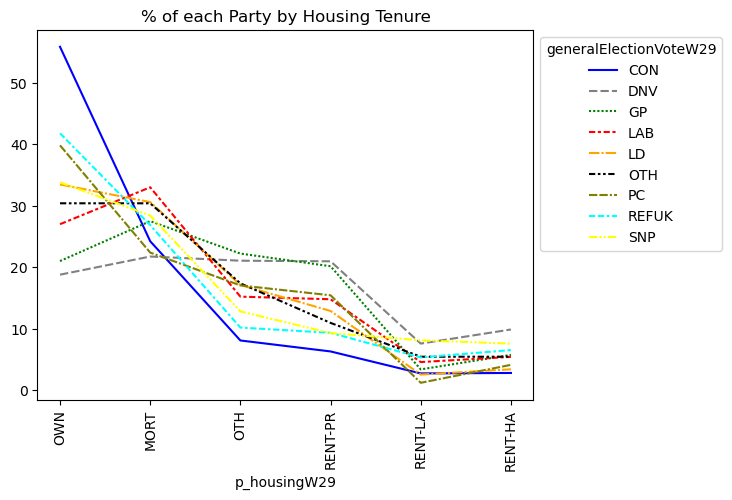

In [165]:

ax = sns.lineplot(pd.crosstab(BES_Panel["p_housingW29"].replace(replace_dict),vote2024,values=BES_Panel["wt_new_W29"],
                         aggfunc=sum,normalize='columns')*100,palette=party_color_dict);
plt.xticks(rotation=90);
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("% of each Party by Housing Tenure");

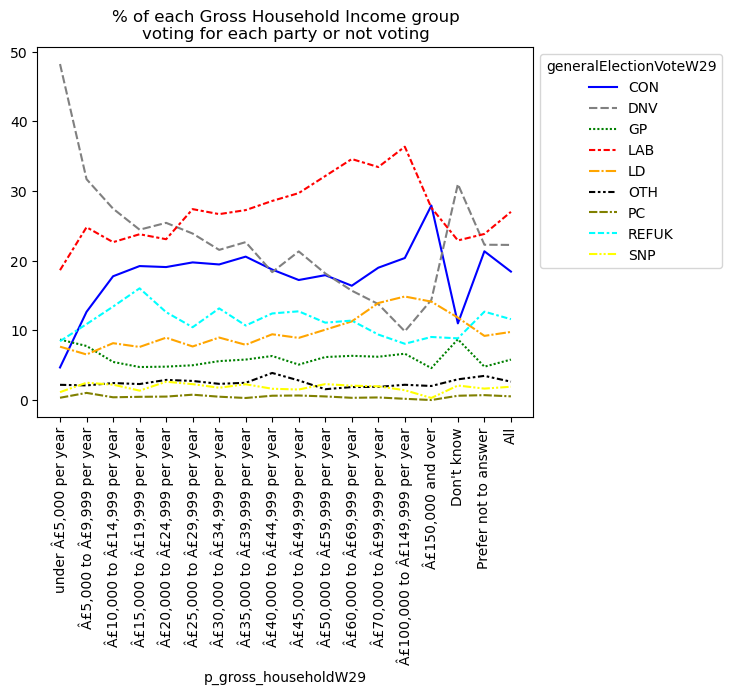

In [158]:


# BES_Panel["p_housingW29"].replace(replace_dict).value_counts()

ax = sns.lineplot(pd.crosstab(BES_Panel["p_gross_householdW29"].replace(replace_dict),vote2024,values=BES_Panel["wt_new_W29"],
                         aggfunc=sum,normalize='index',margins=True)*100,palette=party_color_dict);
plt.xticks(rotation=90);
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("% of each Gross Household Income group\nvoting for each party or not voting");

In [178]:
party_color_dict = {'Con': 'blue','CON': 'blue',
 'Lab': 'red','LAB': 'red',
 'LD': 'orange',
 'Grn': 'green','GP': 'green',
 'BNP': 'black',"DNV":"grey","OTH":"black",
 'UKIP': 'purple',
 'BrexitParty': 'cyan','REFUK': 'cyan',
 'PC': 'olive',
 'SNP': 'yellow','All':'black'}

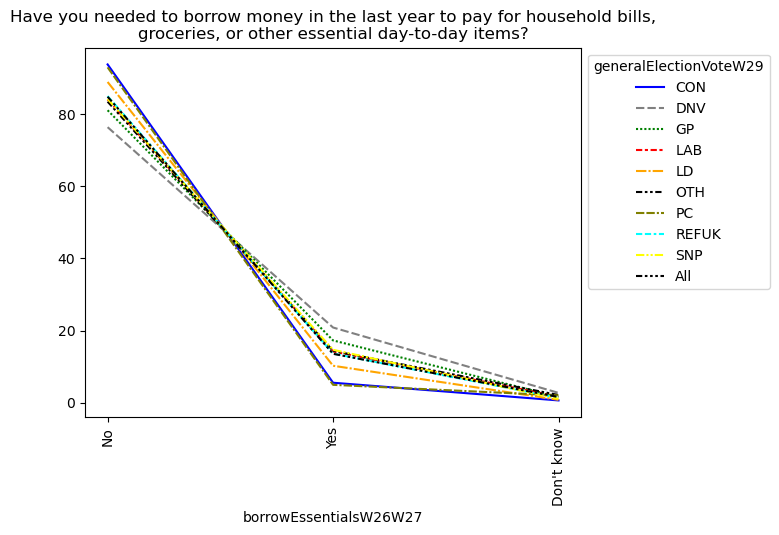

In [180]:
ax = sns.lineplot(pd.crosstab(BES_Panel["borrowEssentialsW26W27"].replace(replace_dict),vote2024,values=BES_Panel["wt_new_W29"],
                         aggfunc=sum,normalize='columns',margins=True)*100,palette=party_color_dict);
plt.xticks(rotation=90);
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("Have you needed to borrow money in the last year to pay for household bills,\ngroceries, or other essential day-to-day items?");

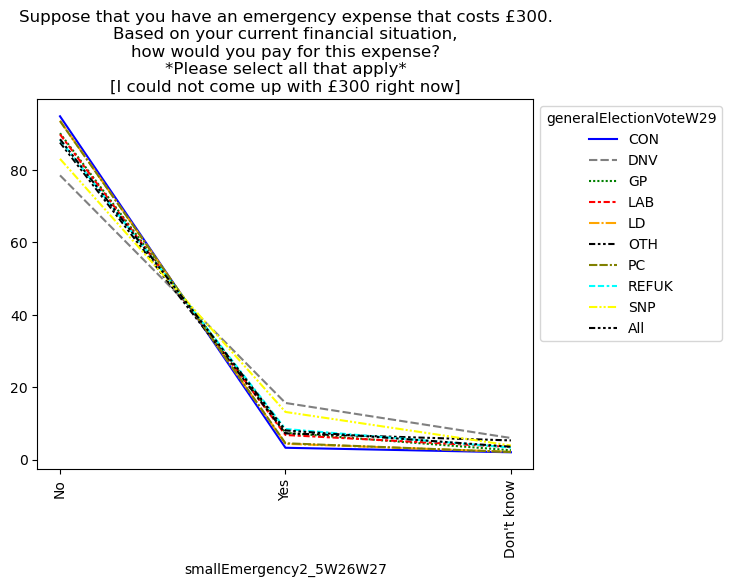

In [186]:
ax = sns.lineplot(pd.crosstab(BES_Panel["smallEmergency2_5W26W27"].replace(replace_dict),vote2024,values=BES_Panel["wt_new_W29"],
                         aggfunc=sum,normalize='columns',margins=True)*100,palette=party_color_dict);
plt.xticks(rotation=90);
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("Suppose that you have an emergency expense that costs £300.\nBased on your current financial situation,\nhow would you pay for this expense?\n*Please select all that apply*\n[I could not come up with £300 right now]");